Task 1: Load the Dataset. In this step I load the Olivetti Faces pictures. It has 400 black and white face pictures of 40 different people, with 10 pictures of each person. Each picture is 64 by 64 pixels, so I turn each one into a single row of 4,096 numbers, one for each pixel. I print the number of pictures, the number of different people, and the number of values in each row to make sure everything loaded correctly. Then I show 20 faces in a grid with 4 rows and 5 columns, each one labeled with the ID of the person in the picture.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Total samples: 400
Unique subjects: 40
Feature dimensions: 4096


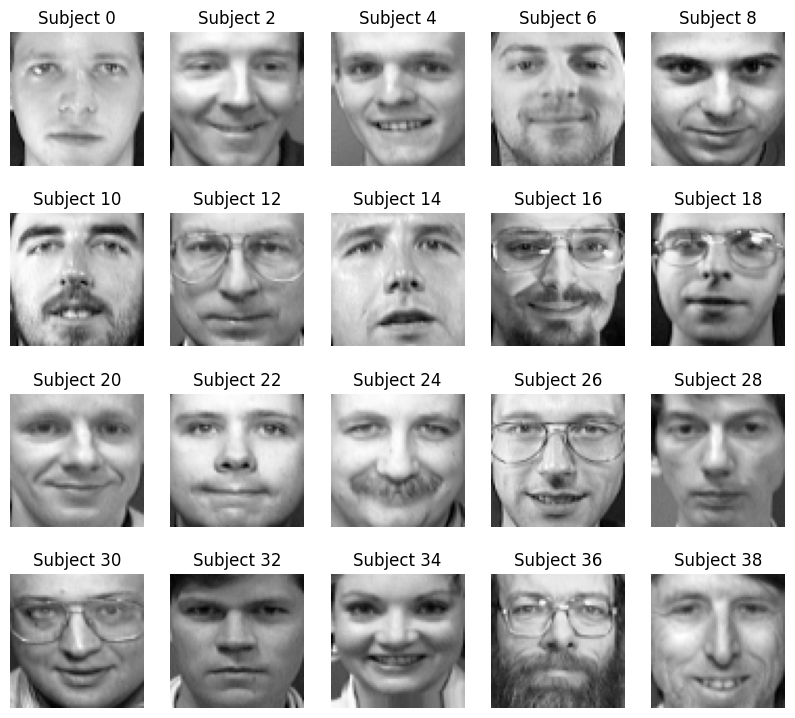

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces()
X = faces.data
y = faces.target
images = faces.images

print("Total samples:", X.shape[0])
print("Unique subjects:", len(np.unique(y)))
print("Feature dimensions:", X.shape[1])

fig, axes = plt.subplots(4, 5, figsize=(10, 9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(images[i * 20], cmap="gray")
    ax.set_title(f"Subject {y[i * 20]}")
    ax.axis("off")
plt.show()

Task 2: Explained Variance and Elbow Plot. In this step I run PCA on the faces. PCA looks at all 4,096 pixel values and builds a new, shorter set of values that keeps as much of the important information about the faces as it can. Each new value is called a principal component, and they are ordered from the most useful to the least useful. For each component I find how much of the total information it holds. I draw two plots. The first shows how much each single component holds, and it drops off quickly, which is the elbow. The second adds them up as I go, so I can see how much of the total is kept after using a certain number of components.

Components for 90% variance: 66
Components for 95% variance: 123
Components for 99% variance: 260


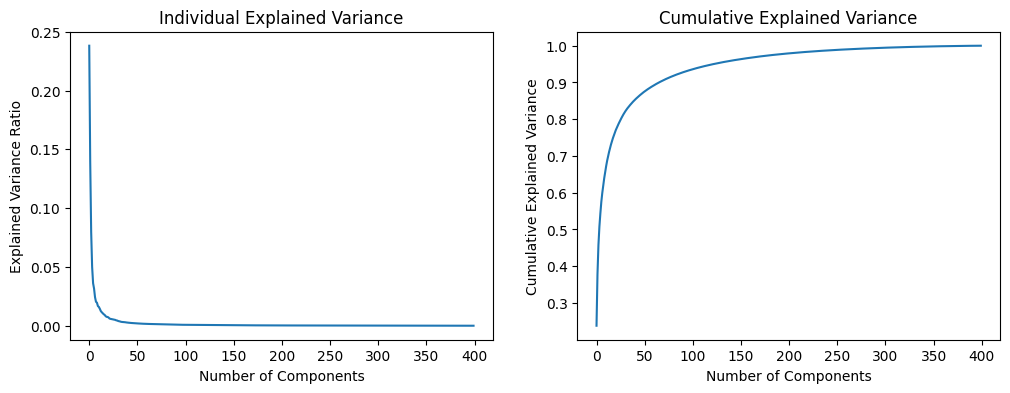

In [2]:
from sklearn.decomposition import PCA

pca = PCA()
pca.fit(X)

ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)

for p in [0.90, 0.95, 0.99]:
    k = np.argmax(cumulative >= p) + 1
    print(f"Components for {int(p * 100)}% variance:", k)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ratio)
axes[0].set_title("Individual Explained Variance")
axes[0].set_xlabel("Number of Components")
axes[0].set_ylabel("Explained Variance Ratio")
axes[1].plot(cumulative)
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Explained Variance")
plt.show()

Task 3: Image Compression and Reconstruction. In this step I pick 5 faces, each from a different person, and test how well PCA can shrink and rebuild them. For each number of components I test, I squeeze the face down to that many values, which is the compression, and then rebuild the picture from those values. With only a few components the rebuilt face loses detail, and with more components it looks closer to the original. I draw a grid with the original faces in the first column and the rebuilt versions next to them for each number of components.

k = 10, MSE = 0.00577
k = 50, MSE = 0.00214
k = 100, MSE = 0.00109
k = 200, MSE = 0.00040
k = 300, MSE = 0.00013


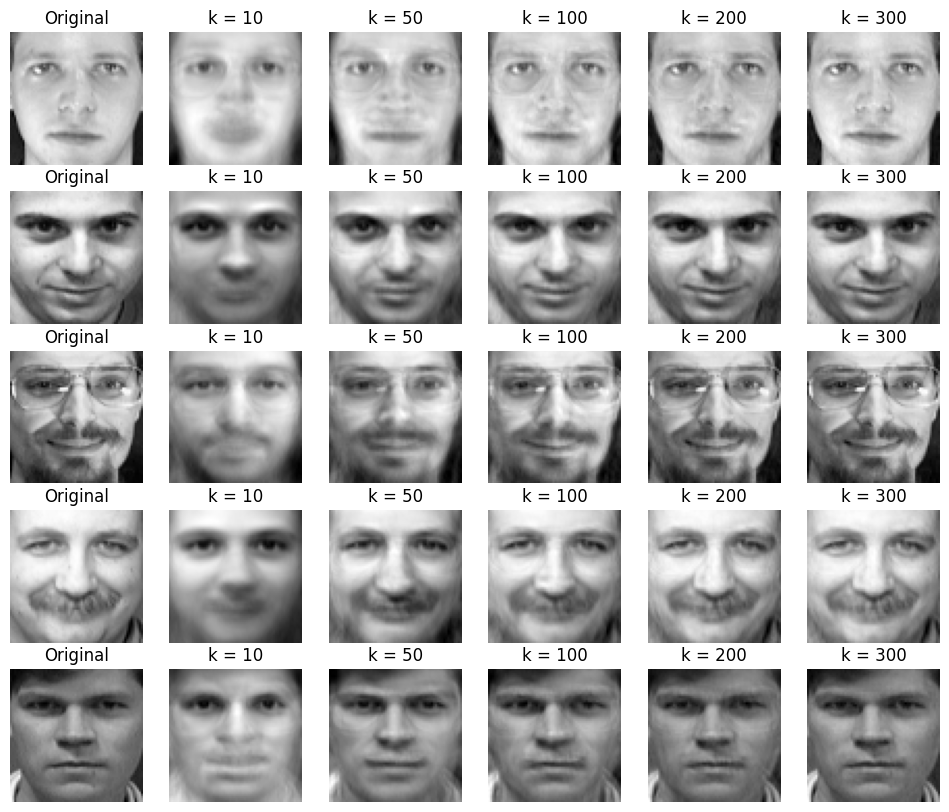

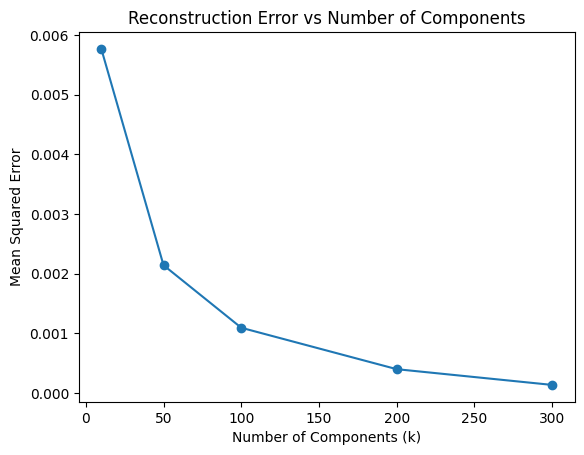

In [3]:
picks = [0, 80, 160, 240, 320]
ks = [10, 50, 100, 200, 300]

recon = {}
mse = []
for k in ks:
    p = PCA(n_components=k)
    p.fit(X)
    rebuilt = p.inverse_transform(p.transform(X[picks]))
    recon[k] = rebuilt
    mse.append(np.mean((X[picks] - rebuilt) ** 2))
    print(f"k = {k}, MSE = {mse[-1]:.5f}")

fig, axes = plt.subplots(5, 6, figsize=(12, 10))
for row, idx in enumerate(picks):
    axes[row, 0].imshow(X[idx].reshape(64, 64), cmap="gray")
    axes[row, 0].set_title("Original")
    for col, k in enumerate(ks):
        axes[row, col + 1].imshow(recon[k][row].reshape(64, 64), cmap="gray")
        axes[row, col + 1].set_title(f"k = {k}")
for ax in axes.ravel():
    ax.axis("off")
plt.show()

plt.plot(ks, mse, marker="o")
plt.xlabel("Number of Components (k)")
plt.ylabel("Mean Squared Error")
plt.title("Reconstruction Error vs Number of Components")
plt.show()

Task 4: Eigenfaces. In this step I look at the principal components themselves. Each component is a list of 4,096 numbers, one for each pixel, so I can turn it back into a 64 by 64 picture. Each one shows a pattern that PCA found in the faces, like a certain lighting direction or face shape, and every face in the dataset can be built by mixing these patterns together.  Above each one I print the percentage of the total information that component holds.

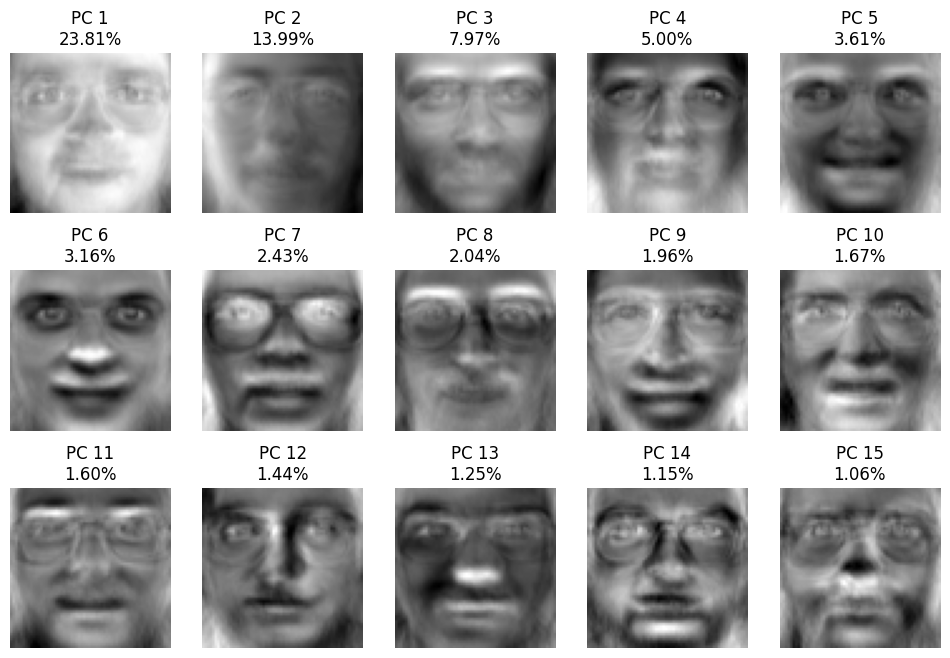

In [4]:
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(pca.components_[i].reshape(64, 64), cmap="gray")
    ax.set_title(f"PC {i + 1}\n{ratio[i] * 100:.2f}%")
    ax.axis("off")
plt.show()

Task 5: Logistic Regression on Raw Pixels vs PCA. In this step I split the 400 faces into a training set and a test set. Then I train a Logistic Regression model two ways. The first uses all 4,096 raw pixel values for each face. For the second, I run PCA on the training faces only, keeping enough components to hold 95% of the information, and then train the model on those. For each version I time the training, with the PCA step included in the second one, and measure the accuracy on the test set. I show both in a bar plot with two y-axes, with accuracy on the left and training time on the right.

PCA components used: 111
Raw: accuracy = 0.9625, time = 29.73s
PCA: accuracy = 0.9625, time = 0.93s


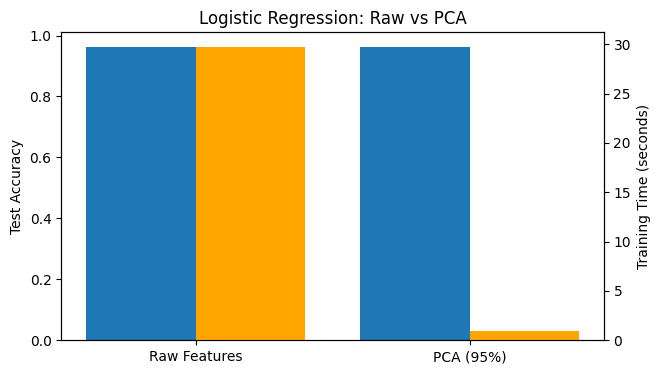

In [5]:
import time
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

start = time.time()
lr_raw = LogisticRegression(max_iter=1000)
lr_raw.fit(X_train, y_train)
t_raw = time.time() - start
acc_raw = lr_raw.score(X_test, y_test)

start = time.time()
pca95 = PCA(n_components=0.95)
X_train_pca = pca95.fit_transform(X_train)
lr_pca = LogisticRegression(max_iter=1000)
lr_pca.fit(X_train_pca, y_train)
t_pca = time.time() - start
X_test_pca = pca95.transform(X_test)
acc_pca = lr_pca.score(X_test_pca, y_test)

print("PCA components used:", pca95.n_components_)
print(f"Raw: accuracy = {acc_raw:.4f}, time = {t_raw:.2f}s")
print(f"PCA: accuracy = {acc_pca:.4f}, time = {t_pca:.2f}s")

labels = ["Raw Features", "PCA (95%)"]
x = np.arange(2)
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.bar(x - 0.2, [acc_raw, acc_pca], 0.4, label="Accuracy")
ax1.set_ylabel("Test Accuracy")
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax2 = ax1.twinx()
ax2.bar(x + 0.2, [t_raw, t_pca], 0.4, color="orange", label="Training Time")
ax2.set_ylabel("Training Time (seconds)")
plt.title("Logistic Regression: Raw vs PCA")
plt.show()

Task 6: Kernel SVM on PCA Features. In this step I train a Support Vector Classifier with an RBF kernel on the same PCA features from Task 5. I time the training the same way as before, with the PCA step included, and measure the accuracy on the test set. Then I draw a confusion matrix for the SVC and one for the Logistic Regression model side by side. A confusion matrix shows which person each test face was guessed to be, so a perfect model has a clean diagonal line, and any dot off the line is a mistake.

SVC: accuracy = 0.9375, time = 0.30s
Logistic Regression (PCA): accuracy = 0.9625


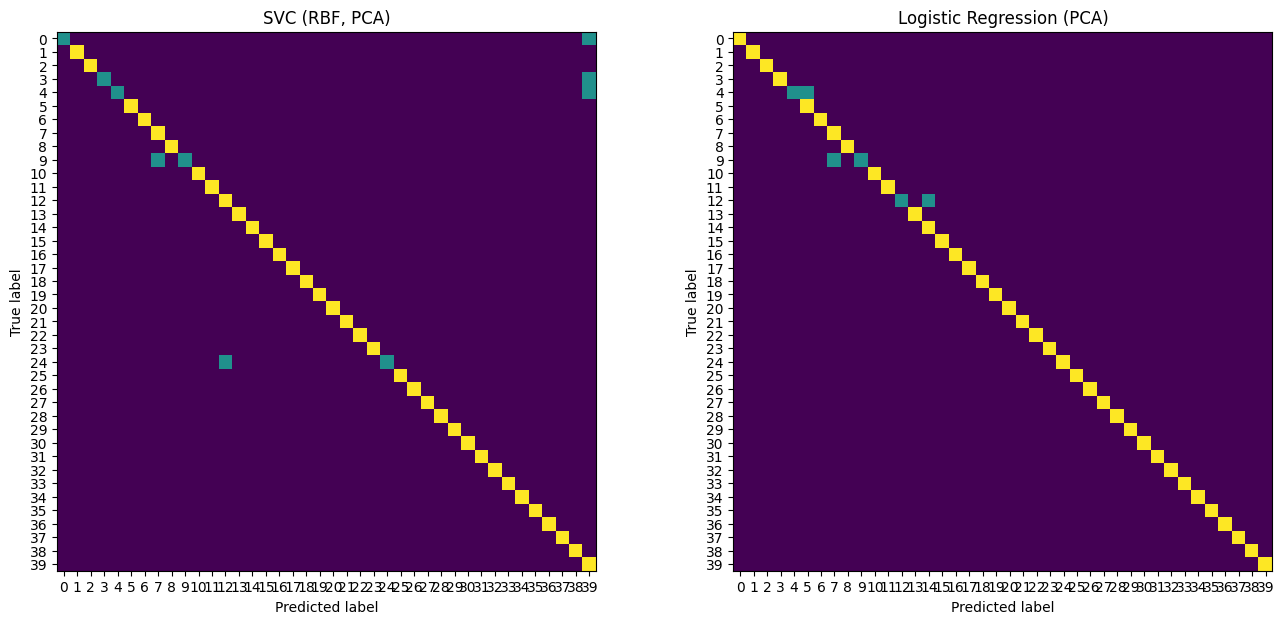

In [6]:
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay

start = time.time()
pca_t = PCA(n_components=0.95)
pca_t.fit(X_train)
t_pca_fit = time.time() - start

start = time.time()
svc = SVC(kernel="rbf")
svc.fit(X_train_pca, y_train)
t_svc = (time.time() - start) + t_pca_fit
acc_svc = svc.score(X_test_pca, y_test)

print(f"SVC: accuracy = {acc_svc:.4f}, time = {t_svc:.2f}s")
print(f"Logistic Regression (PCA): accuracy = {acc_pca:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ConfusionMatrixDisplay.from_predictions(y_test, svc.predict(X_test_pca), ax=axes[0], colorbar=False, include_values=False)
axes[0].set_title("SVC (RBF, PCA)")
ConfusionMatrixDisplay.from_predictions(y_test, lr_pca.predict(X_test_pca), ax=axes[1], colorbar=False, include_values=False)
axes[1].set_title("Logistic Regression (PCA)")
plt.show()

Task 7: Voting Ensemble on PCA Features. In this step I combine three different models into one team that votes on each face an SVC with a polynomial kernel, an SVC with an RBF kernel, and a Random Forest with 100 trees. I use soft voting. I set probability=True on both SVCs so they can give those chances. I train the team on the same PCA features as before, time it with the PCA step included, and measure the accuracy on the test set. Then I print the result next to Logistic Regression and the RBF SVC so I can see whether combining models helps.

In [7]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier

start = time.time()
ensemble = VotingClassifier(
    estimators=[
        ("poly", SVC(kernel="poly", degree=2, probability=True, random_state=42)),
        ("rbf", SVC(kernel="rbf", probability=True, random_state=42)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42))],
    voting="soft")
ensemble.fit(X_train_pca, y_train)
t_ens = (time.time() - start) + t_pca_fit
acc_ens = ensemble.score(X_test_pca, y_test)

print(f"Ensemble: accuracy = {acc_ens:.4f}, time = {t_ens:.2f}s")
print(f"SVC (RBF): accuracy = {acc_svc:.4f}, time = {t_svc:.2f}s")
print(f"Logistic Regression (PCA): accuracy = {acc_pca:.4f}, time = {t_pca:.2f}s")

Ensemble: accuracy = 0.9500, time = 2.00s
SVC (RBF): accuracy = 0.9375, time = 0.30s
Logistic Regression (PCA): accuracy = 0.9625, time = 0.93s


Task 8: Final Comparison. In this step I put all four models into one chart so I can compare them side by side. Logistic Regression on the raw pixels, Logistic Regression on the PCA features, the RBF SVC on the PCA features, and the soft voting ensemble on the PCA features. For each one I show the test accuracy as a bar on the left y-axis and the training time in seconds as a bar on the right y-axis. I use the numbers I saved from the earlier tasks, so nothing is trained again.

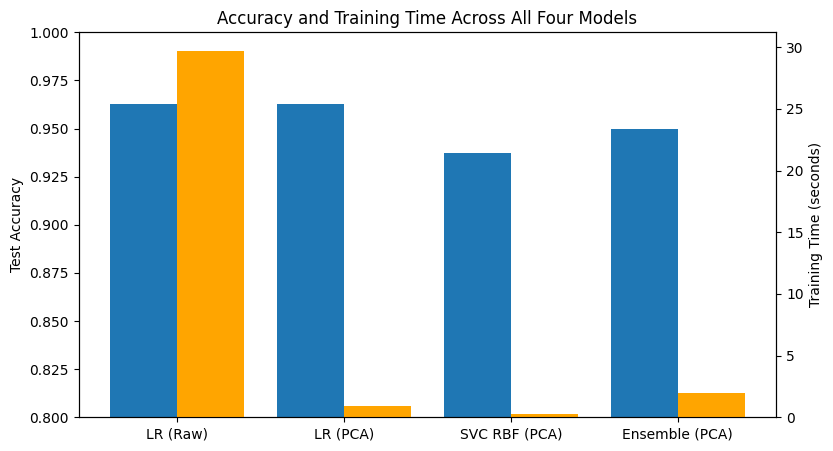

LR (Raw): accuracy = 0.9625, time = 29.73s
LR (PCA): accuracy = 0.9625, time = 0.93s
SVC RBF (PCA): accuracy = 0.9375, time = 0.30s
Ensemble (PCA): accuracy = 0.9500, time = 2.00s


In [8]:
names = ["LR (Raw)", "LR (PCA)", "SVC RBF (PCA)", "Ensemble (PCA)"]
accs = [acc_raw, acc_pca, acc_svc, acc_ens]
times = [t_raw, t_pca, t_svc, t_ens]

x = np.arange(4)
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.bar(x - 0.2, accs, 0.4, label="Accuracy")
ax1.set_ylabel("Test Accuracy")
ax1.set_ylim(0.8, 1.0)
ax1.set_xticks(x)
ax1.set_xticklabels(names)
ax2 = ax1.twinx()
ax2.bar(x + 0.2, times, 0.4, color="orange", label="Training Time")
ax2.set_ylabel("Training Time (seconds)")
plt.title("Accuracy and Training Time Across All Four Models")
plt.show()

for n, a, t in zip(names, accs, times):
    print(f"{n}: accuracy = {a:.4f}, time = {t:.2f}s")